

*   Name : Molemi Molokoane
*   Email : iimillicent02@gmail.com



## Dataset Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [ ]:
import os, glob
import pandas as pd

FILES = ["olist_orders_dataset.csv", "olist_order_items_dataset.csv",
         "olist_order_reviews_dataset.csv", "olist_products_dataset.csv"]

# search the whole Drive for the Olist files
DATA_DIR = None
try:
    from google.colab import drive
    drive.mount("/content/drive")
    found = glob.glob("/content/drive/MyDrive/**/olist_orders_dataset.csv", recursive=True)
    if found:
        DATA_DIR = os.path.dirname(found[0])
except ImportError:
    pass


orders = pd.read_csv(os.path.join(DATA_DIR, "olist_orders_dataset.csv"))
order_items = pd.read_csv(os.path.join(DATA_DIR, "olist_order_items_dataset.csv"))
reviews = pd.read_csv(os.path.join(DATA_DIR, "olist_order_reviews_dataset.csv"))
products = pd.read_csv(os.path.join(DATA_DIR, "olist_products_dataset.csv"))

for name, df in {"orders": orders, "order_items": order_items, "reviews": reviews, "products": products}.items():
    print(f"- {name}: {df.shape[0]:,} rows, {df.shape[1]} columns")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
- orders: 99,441 rows, 8 columns
- order_items: 112,650 rows, 7 columns
- reviews: 99,224 rows, 7 columns
- products: 32,951 rows, 9 columns


---
## Part A: Defensible Data Quality Audit (5-Point Analysis)

### Issue 1: Missing Temporal Timestamps in Orders

* **Dataset & Column:** `orders` → `order_delivered_customer_date`
* **Dimension Violated:** Completeness
* **Evidence:** see code below — 2,965 orders (≈3.0%) have no customer delivery date. Almost all of them are non-delivered statuses (shipped, canceled, unavailable, …), but **8 orders are marked `delivered` with no delivery date**, which is a genuine integrity error.
* **Business Impact:** Average delivery time computed only on rows with a date silently drops delayed/failed orders, so logistics performance looks better than it is.
* **Cleaning Plan:** Add an `is_delivered` flag, isolate `delivered`-but-null rows for verification, and do not impute dates.

In [ ]:
missing_delivery = orders["order_delivered_customer_date"].isnull()
print(f"Missing delivery dates: {missing_delivery.sum():,} of {len(orders):,} ({missing_delivery.mean():.2%})")

print("\nOrder status of rows missing a delivery date:")
print(orders.loc[missing_delivery, "order_status"].value_counts())

Missing delivery dates: 2,965 of 99,441 (2.98%)

Order status of rows missing a delivery date:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [ ]:
# Cleaning plan: flag, isolate, do not impute
orders_clean = orders.copy()
orders_clean["is_delivered"] = orders_clean["order_delivered_customer_date"].notnull()

integrity_issues = orders_clean[(orders_clean["order_status"] == "delivered") & ~orders_clean["is_delivered"]]
print(f"'delivered' orders with no delivery date (flagged for verification): {len(integrity_issues)}")
integrity_issues[["order_id", "order_status", "order_purchase_timestamp", "order_delivered_carrier_date"]]

'delivered' orders with no delivery date (flagged for verification): 8


,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-30 18:12:23
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-25 08:05:00
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,2018-07-03 13:57:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,2018-07-03 13:57:00
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,2018-07-03 09:28:00
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,NaN
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,2018-06-12 14:10:00
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,2018-07-03 19:26:00


### Issue 2: Extreme Outliers in Product Prices

* **Dataset & Column:** `order_items` → `price`
* **Dimension Violated:** Validity (Range & Distribution)
* **Evidence:** max price is 6,735.00 while the median is 74.99; skewness ≈ 7.9 (> 7.0). About 8,400 line items sit above the 1.5×IQR upper fence.
* **Business Impact:** Regression-style models are pulled toward extreme values, distorting sales forecasts and pricing policies.
* **Cleaning Plan:** Keep the rows (they are real high-value sales); use a log transform or IQR-based robust scaling for modelling.

In [ ]:
price = order_items["price"]
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

print(f"Max price:    {price.max():,.2f}")
print(f"Median price: {price.median():,.2f}")
print(f"Mean price:   {price.mean():,.2f}")
print(f"Skewness:     {price.skew():.2f}")
print(f"IQR upper fence: {upper_fence:,.2f} -> {(price > upper_fence).sum():,} outlier rows ({(price > upper_fence).mean():.1%})")

Max price:    6,735.00
Median price: 74.99
Mean price:   120.65
Skewness:     7.92
IQR upper fence: 277.40 -> 8,427 outlier rows (7.5%)


In [ ]:
# Cleaning plan: keep the rows, add model-friendly versions of the column
order_items_clean = order_items.copy()
order_items_clean["price_log"] = np.log1p(order_items_clean["price"])
order_items_clean["price_robust"] = (order_items_clean["price"] - price.median()) / iqr

print(f"Skewness raw: {price.skew():.2f} | after log1p: {order_items_clean['price_log'].skew():.2f}")
print(f"Rows kept: {len(order_items_clean):,} (none dropped)")

Skewness raw: 7.92 | after log1p: 0.29
Rows kept: 112,650 (none dropped)


### Issue 3: Missing Catalog Product Categories

* **Dataset & Column:** `products` → `product_category_name`
* **Dimension Violated:** Completeness
* **Evidence:** 610 products have no category name.
* **Business Impact:** Sales and inventory can't be grouped correctly by category; these products vanish from category reports.
* **Cleaning Plan:** Map missing values to `'unclassified'` so their transactions stay in revenue analysis.

In [ ]:
missing_cat = products["product_category_name"].isnull()
print(f"Products missing a category: {missing_cat.sum():,} of {len(products):,} ({missing_cat.mean():.2%})")

# How much sales volume do these products carry?
uncat_ids = products.loc[missing_cat, "product_id"]
uncat_items = order_items[order_items["product_id"].isin(uncat_ids)]
print(f"Order line items for these products: {len(uncat_items):,} (revenue {uncat_items['price'].sum():,.2f})")

Products missing a category: 610 of 32,951 (1.85%)
Order line items for these products: 1,603 (revenue 179,535.28)


In [ ]:
products_clean = products.copy()
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unclassified")
print(products_clean["product_category_name"].isnull().sum(), "missing after cleaning")
print((products_clean["product_category_name"] == "unclassified").sum(), "products labelled 'unclassified'")

0 missing after cleaning
610 products labelled 'unclassified'


### Issue 4: Duplicate Review Submissions Across Orders

* **Dataset & Column:** `reviews` → `review_id`
* **Dimension Violated:** Consistency / Integrity
* **Evidence:** 814 extra rows reuse an existing `review_id` (1,603 rows involved in total). Separately, 551 orders have more than one review.
* **Business Impact:** Joining on non-unique keys multiplies rows, inflating revenue and feedback metrics.
* **Cleaning Plan:** Before joining, keep only the latest submission (by `review_answer_timestamp`).

In [ ]:
dup_review_rows = reviews["review_id"].duplicated().sum()
rows_involved = reviews["review_id"].duplicated(keep=False).sum()
print(f"Total reviews: {len(reviews):,} | unique review_id: {reviews['review_id'].nunique():,}")
print(f"Duplicate review_id rows (extra copies): {dup_review_rows:,}")
print(f"Rows sharing a review_id with another row: {rows_involved:,}")
print(f"Orders with more than one review: {reviews['order_id'].duplicated().sum():,}")

# Show the join inflation this causes
joined = orders.merge(reviews, on="order_id", how="left")
print(f"\norders rows: {len(orders):,} -> after joining reviews: {len(joined):,} (+{len(joined) - len(orders):,})")

Total reviews: 99,224 | unique review_id: 98,410
Duplicate review_id rows (extra copies): 814
Rows sharing a review_id with another row: 1,603
Orders with more than one review: 551

orders rows: 99,441 -> after joining reviews: 99,992 (+551)


In [ ]:
reviews_clean = reviews.copy()
reviews_clean["review_answer_timestamp"] = pd.to_datetime(reviews_clean["review_answer_timestamp"])

# Keep the latest submission per review_id, then per order so the join is one-to-one
reviews_clean = (reviews_clean.sort_values("review_answer_timestamp")
                 .drop_duplicates(subset="review_id", keep="last")
                 .drop_duplicates(subset="order_id", keep="last"))

joined_clean = orders.merge(reviews_clean, on="order_id", how="left")
print(f"Reviews after dedup: {len(reviews_clean):,}")
print(f"orders rows: {len(orders):,} -> after joining clean reviews: {len(joined_clean):,}")

Reviews after dedup: 98,140
orders rows: 99,441 -> after joining clean reviews: 99,441


### Issue 5: Products Catalogued with 0 Grams of Weight

* **Dataset & Column:** `products` → `product_weight_g`
* **Dimension Violated:** Accuracy
* **Evidence:** 4 products have a weight of exactly 0 g (all in `cama_mesa_banho`, bed/bath/table). 2 more have no weight at all.
* **Business Impact:** Automated freight calculators would quote zero shipping cost, causing losses on fulfilment.
* **Cleaning Plan:** Replace 0 g with the median weight of the same category (computed excluding zeros).

In [ ]:
zero_weight = products["product_weight_g"] == 0
print(f"Products with weight = 0g: {zero_weight.sum()}")
print(f"Products with missing weight: {products['product_weight_g'].isnull().sum()}")
products.loc[zero_weight, ["product_id", "product_category_name", "product_weight_g",
                           "product_length_cm", "product_height_cm", "product_width_cm"]]

Products with weight = 0g: 4
Products with missing weight: 2


,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,0.0,30.0,25.0,30.0


In [ ]:
# Category median weight, ignoring the invalid zeros
valid_weight = products_clean["product_weight_g"].where(products_clean["product_weight_g"] > 0)
category_median = valid_weight.groupby(products_clean["product_category_name"]).transform("median")

zero_mask = products_clean["product_weight_g"] == 0
products_clean.loc[zero_mask, "product_weight_g"] = category_median[zero_mask]

print(f"Zero-weight products after cleaning: {(products_clean['product_weight_g'] == 0).sum()}")
products_clean.loc[zero_mask, ["product_id", "product_category_name", "product_weight_g"]]

Zero-weight products after cleaning: 0


,product_id,product_category_name,product_weight_g
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,1250.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,1250.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,1250.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,1250.0


---
## Part B: Practical Visualization Recall

### Task 1: Price Distribution & Outliers

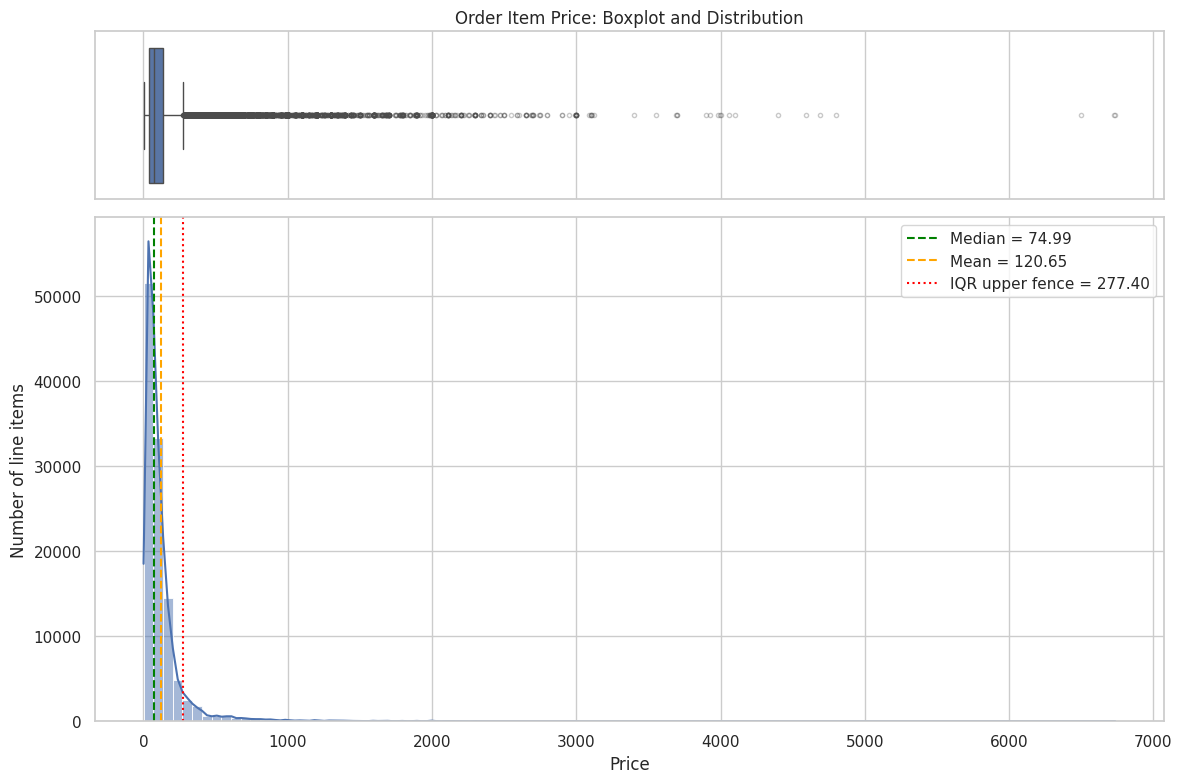

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [1, 3]})

sns.boxplot(x=order_items["price"], ax=axes[0], color="#4C72B0", flierprops={"marker": ".", "alpha": 0.3})
axes[0].set_title("Order Item Price: Boxplot and Distribution")
axes[0].set_xlabel("")

sns.histplot(order_items["price"], bins=100, kde=True, ax=axes[1], color="#4C72B0")
axes[1].axvline(order_items["price"].median(), color="green", linestyle="--", label=f"Median = {order_items['price'].median():.2f}")
axes[1].axvline(order_items["price"].mean(), color="orange", linestyle="--", label=f"Mean = {order_items['price'].mean():.2f}")
axes[1].axvline(upper_fence, color="red", linestyle=":", label=f"IQR upper fence = {upper_fence:.2f}")
axes[1].set_xlabel("Price")
axes[1].set_ylabel("Number of line items")
axes[1].legend()

plt.tight_layout()
plt.show()

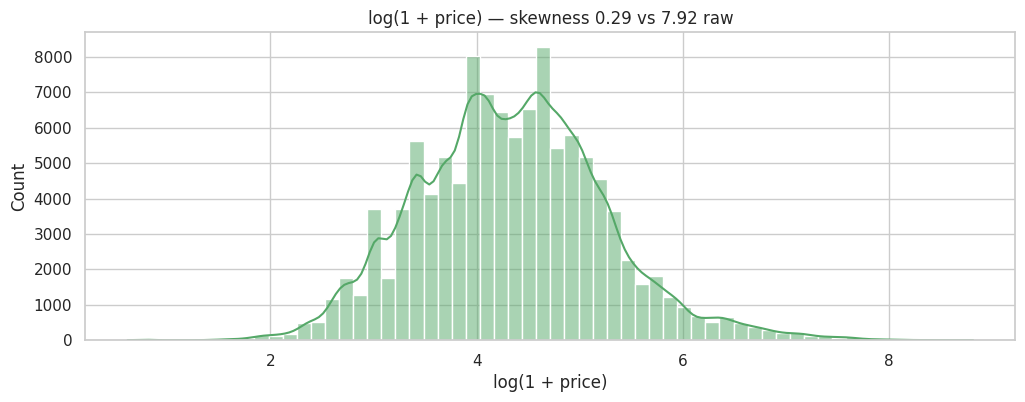

In [ ]:
# Same data on a log scale: the long tail becomes readable
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(order_items_clean["price_log"], bins=60, kde=True, ax=ax, color="#55A868")
ax.set_title(f"log(1 + price) — skewness {order_items_clean['price_log'].skew():.2f} vs {price.skew():.2f} raw")
ax.set_xlabel("log(1 + price)")
plt.show()

### Task 2: Order Status Breakdown

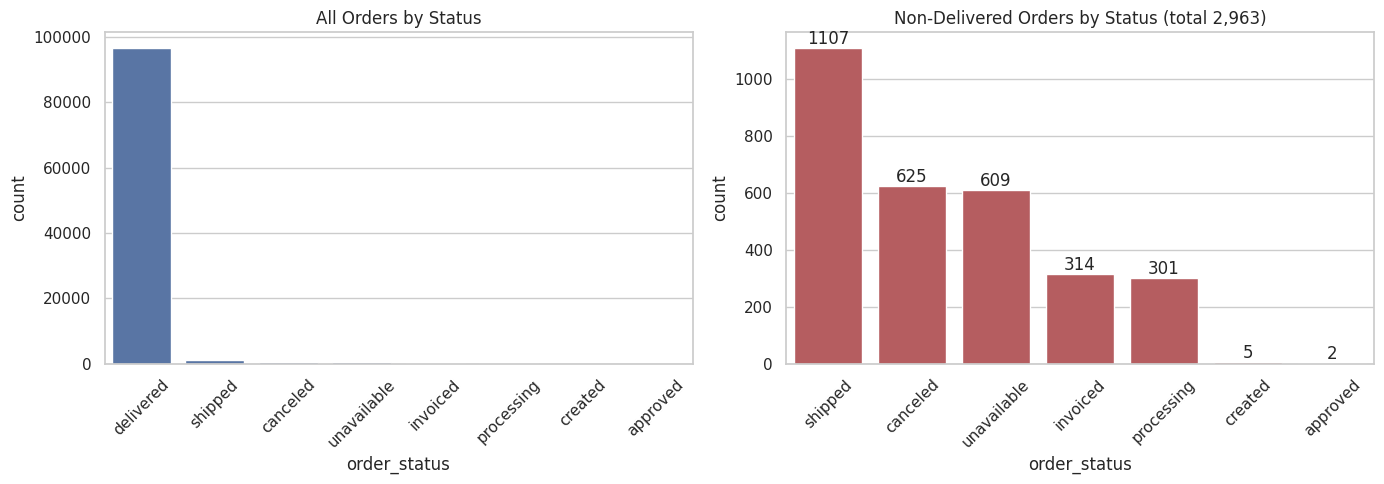

In [ ]:
status_counts = orders["order_status"].value_counts().reset_index()
status_counts.columns = ["order_status", "count"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=status_counts, x="order_status", y="count", ax=axes[0], color="#4C72B0")
axes[0].set_title("All Orders by Status")
axes[0].tick_params(axis="x", rotation=45)

# Without 'delivered' so the smaller statuses are visible
non_delivered = status_counts[status_counts["order_status"] != "delivered"]
sns.barplot(data=non_delivered, x="order_status", y="count", ax=axes[1], color="#C44E52")
axes[1].set_title(f"Non-Delivered Orders by Status (total {non_delivered['count'].sum():,})")
axes[1].tick_params(axis="x", rotation=45)
for container in axes[1].containers:
    axes[1].bar_label(container)

plt.tight_layout()
plt.show()

---
## Part C: Written Reflection

**Numerical vs. visual auditing.** The summary numbers told me *that* there were problems, but the plots showed me *what shape* they had. `.describe()` reports a max price of 6,735 and a mean (120.65) above the median (74.99), but the boxplot and histogram make it obvious that this is not a handful of typos: there is a long, continuous right tail with thousands of points past the IQR fence, and almost all of the mass sits below about 200. That changes the treatment — a continuous tail of real sales calls for a log transform, not deletion. Likewise, `.isnull().sum()` gives 2,965 missing delivery dates as one number, while the status bar chart shows those orders are spread across shipped, canceled, unavailable, invoiced and processing. The missing dates are mostly a symptom of order state, not random gaps, and the chart without `delivered` makes the ~3,000 non-delivered orders visible instead of being dwarfed by 96,478 delivered ones.

**Defensible business decisions.** Blindly running `df.dropna()` on `orders` would remove every order without a delivery date — i.e. every shipped, canceled and unavailable order. Any delivery-time or fulfilment KPI computed afterwards would describe only the orders that went well, hiding exactly the failures the operations team needs to see. Dropping statistical outliers in `price` is just as risky: those ~8,400 rows above the fence are real, high-value transactions, so removing them would understate revenue and bias any pricing model toward cheap items. In e-commerce, unusual rows are often the most commercially important ones, so the defensible approach is to flag, isolate or transform them, and to delete only rows that are demonstrably invalid.